model.coef_: [30.]
model.intercept_: 200.00000000000045
R2: 1.0
Mean squared error: 0.00


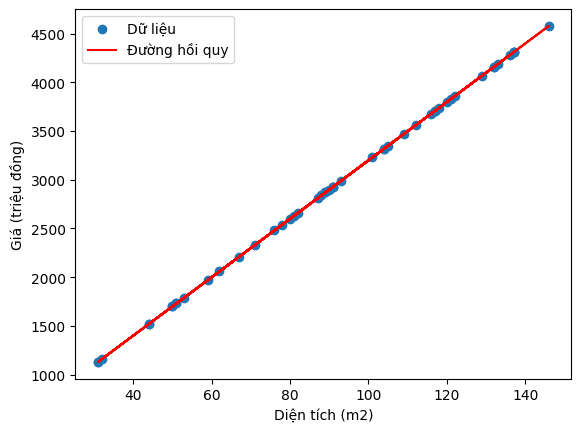

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score

np.random.seed(42)
n=50
dien_tich = np.random.randint(30, 150, n)
gia=30*dien_tich +200
X=dien_tich.reshape(-1,1)
y=gia
X_train, X_test, y_train, y_test = train_test_split(dien_tich.reshape(-1, 1), y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("model.coef_:", model.coef_)
print("model.intercept_:", model.intercept_)
print("R2:",r2_score(y_test, y_pred))
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
plt.scatter(X,y, label="Dữ liệu")
plt.plot(X, model.predict(X), color='red', label="Đường hồi quy")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá (triệu đồng)")
plt.legend()
plt.show()

In [26]:
def them_nhieu(n,noise_std):
    np.random.seed(0)
    dien_tich = np.random.randint(30, 150, n)
    nhieu = np.random.normal(0, noise_std, n)
    gia = 30 * dien_tich + 200 + nhieu
    X = dien_tich.reshape(-1, 1)
    y = gia
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return model.coef_[0], model.intercept_, mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)
rows = []
for noise_std in [0,20,100,1000]:
    for n in[20,100,500]:
        a,b,mse,r2=them_nhieu(n,noise_std)
        rows.append([n,noise_std,a,b,mse,r2])
df_kq=pd.DataFrame(rows,columns=["n","noise_std","coef_","intercept_","mse","r2"])
print(df_kq)

      n  noise_std      coef_  intercept_           mse        r2
0    20          0  30.000000  200.000000  0.000000e+00  1.000000
1   100          0  30.000000  200.000000  0.000000e+00  1.000000
2   500          0  30.000000  200.000000  2.378144e-26  1.000000
3    20         20  30.230315  187.248070  3.390057e+02  0.998746
4   100         20  29.966244  204.787406  3.617157e+02  0.999740
5   500         20  30.012409  195.944865  5.150497e+02  0.999525
6    20        100  31.151573  136.240348  8.475143e+03  0.968382
7   100        100  29.831219  223.937031  9.042892e+03  0.993724
8   500        100  30.062045  179.724325  1.287624e+04  0.988364
9    20       1000  41.515727 -437.596522  8.475143e+05  0.011761
10  100       1000  28.312193  439.370311  9.042892e+05  0.666431
11  500       1000  30.620451   -2.756752  1.287624e+06  0.478932


In [27]:
np.random.seed(36)
n=300
dien_tich = np.random.randint(30, 150, n)
co_nha_= np.random.randint(0, 2, n)
nhieu = np.random.normal(0, 100, n)
gia=30*dien_tich + 200 + 100*co_nha_+nhieu
df = pd.DataFrame({"dien_tich":dien_tich,"co_nha_":co_nha_,"gia":gia})
print(df.head())
print("Kết quả hồi quy đa biến")
for cols in (["dien_tich"],["dien_tich","co_nha_"]):
    X_train, X_test, y_train, y_test = train_test_split(df[cols], df["gia"], test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)  
    print(cols,"->R2=",round(r2_score(y_test, y_pred),4),"|mse=",round(mean_squared_error(y_test, y_pred),1))
    print("Hệ số:",dict(zip(cols,model.coef_.round(1))),"| Chặn=",round(model.intercept_,1))


   dien_tich  co_nha_          gia
0         35        0  1388.773337
1        128        1  4067.107789
2         60        1  2154.425028
3         70        1  2585.299660
4         63        0  2068.717783
Kết quả hồi quy đa biến
['dien_tich'] ->R2= 0.9886 |mse= 12089.8
Hệ số: {'dien_tich': np.float64(29.7)} | Chặn= 296.2
['dien_tich', 'co_nha_'] ->R2= 0.9912 |mse= 9308.8
Hệ số: {'dien_tich': np.float64(29.7), 'co_nha_': np.float64(86.4)} | Chặn= 248.6
